# Weather data audit — Open-Meteo archive, Delhi

- **Phase:** data gathering and understanding · 
- **Source:** Open-Meteo Archive API (gridded reanalysis)

**Why this audit exists.** 
Weather is only the *input* half of the forecaster,  the target (station PM2.5) comes later.
Before joining the two, we need to know exactly what this series is, what it is *not*, and where it can mislead a model.
Each step below follows the same pattern: **what we are looking for (theory) → code → observations → conclusion / decision**.

## Headline findings

1. **The hourly grid is clean.** 208,440 rows, 2003-01-01 to 2026-10-11, no gaps, duplicates, NaNs or sentinel codes. No imputation is needed for weather.

2. **Timestamps are really IST.** Mean temperature peaks at 14:00 in all four seasons and bottoms out at 05:00–07:00. No timezone shift is needed.

3. **Every flagged value is physical.** The 1,409 "low pressure" hours are all May–September heat-low conditions (my review range was too tight, not the data); winter fog explains 90 % of the humidity = 100 % hours.

4. **⚠ Wind speed has a level shift in November 2024.** From early November 2024 it runs ~2.5 km/h (≈ 30 %) below its own climatology in every season, and hours with wind < 5 km/h jump from 11–20 % of hours a year to about 31–34 %. The cause is unverified (most likely a source/model change), but the planned final test season, 2025–26, lies entirely *after* it.

5. **Issue-time weather has a short reach.** Once the sun and season are removed, wind speed keeps only 0.37 / 0.13 / 0.06 of its autocorrelation at 24 / 48 / 72 h. Knowing today's wind says little about tomorrow's ventilation, so archived *forecast* weather will matter for a 1–3 day forecast.

The full list of decisions and open items is in **Step 11**.

# 1. Setup and load

Everything reusable (structure checks, flat-run detection, wind-rose tables, level-shift search)
lives in `src/aqi/audit.py`, so this notebook only calls it and plots. From the
notebook's `notebooks/` working directory, install it into the active kernel with
`%pip install -e ..`, then restart the kernel before running the import cell.

In [1]:
%pip install -e ..

Obtaining file:///Users/arbazkhan/kael/delhi-aqi-forecast
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for aqi (pyproject.toml) ... done
  Created wheel for aqi: filename=aqi-0.1.0-0.editable-py3-none-any.whl size=3216 sha256=f76a24665bb23fc925dc400038636058c9e964ad868db01a03435cb41599eadd
  Stored in directory: /private/var/folders/t6/83ml_h093hb2vy010z1bgz_m0000gn/T/pip-ephem-wheel-cache-ky5dkzsq/wheels/b1/16/3b/823dba8f3656a1013c218b438e9185be2412b0fd90541b6e59
Successfully built aqi
  Attempting uninstall: aqi
    Found existing installation: aqi 0.1.0
    Uninstalling aqi-0.1.0:
      Successfully uninstalled aqi-0.1.0
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
import importlib.util

#print(sys.executable)
#print(importlib.util.find_spec("aqi"))

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aqi import audit

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.autolayout": True,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.precision", 3)

# Path of the raw data file
RAW_PATH = Path("../data/raw/open_meteo.parquet")

# Meta Data of open-meteo file
META_PATH = Path("../data/raw/open_meteo.meta.json")

meta = json.loads(META_PATH.read_text())
UNITS = meta["units"]
VARS = [c for c in UNITS if c != "time"]

df = audit.load_hourly(RAW_PATH)

pd.Series(
    {
        "requested location": f'{meta["requested"]["lat"]}, {meta["requested"]["lon"]}',
        "grid cell returned": f'{meta["grid_lat"]}, {meta["grid_lon"]}',
        "elevation (m)": meta["elevation"],
        "requested period": f'{meta["requested"]["start"]} to {meta["requested"]["end"]}',
        "timezone requested": meta["timezone"],
        "fetched at (UTC)": meta["fetched_at"],
    },
    name="source metadata",
).to_frame()

,source metadata
requested location,"28.695, 77.181"
grid cell returned,"28.717047, 77.15754"
elevation (m),219.0
requested period,2003-01-01 to 2026-10-11
timezone requested,Asia/Kolkata
fetched at (UTC),2026-10-31T13:25:55.393298+00:00


In [4]:
# Open-meteo API request DataFrame 
df.head()

,temperature_2m,relative_humidity_2m,rain,wind_speed_10m,wind_direction_10m,surface_pressure
time,,,,,,
2003-01-01 00:00:00,9.5,94,0.0,10.9,314,990.2
2003-01-01 01:00:00,9.3,94,0.0,10.5,319,990.6
2003-01-01 02:00:00,9.2,94,0.0,9.1,326,991.0
2003-01-01 03:00:00,9.1,94,0.0,7.3,327,991.5
2003-01-01 04:00:00,9.2,94,0.0,6.6,338,991.9


## Step 1 · Structure and integrity

**What we are looking for.** Time-series methods assume a regular grid: one row per hour, in order, no repeats, no holes.
That assumption is what makes `shift(24)` mean "same hour yesterday" and what makes a walk-forward split meaningful.
One missing hour silently turns every later lag into the wrong hour, with no error raised.


We also record the **record length** (how many autumn–winter seasons exist for validation) and whether timestamps carry a **timezone** (naive timestamps hide misalignment).

**Checks:** index is a `DatetimeIndex` · no duplicates · strictly increasing · every step exactly 1 hour · row count equals the span · no NaNs or sentinel codes (−999, −9999, 9999) · dtypes sensible · coverage per calendar year.

### 1.1 MetaData

In [5]:
# Meta Data fo Data
display(audit.check_structure(df))

,value
rows,208440
first,2003-01-01 00:00:00
last,2026-10-11 23:00:00
years_covered,23.78
timezone,naive (local IST)
duplicates,0
gaps,0


### 1.2 Missing Values

In [6]:
# Missing Values in DataFrame
display(audit.missing_summary(df))

,nan,sentinel
temperature_2m,0,0
relative_humidity_2m,0,0
rain,0,0
wind_speed_10m,0,0
wind_direction_10m,0,0
surface_pressure,0,0


### 1.3 DataType check

In [7]:
# Datatype of each variables 
display(df.dtypes.rename("dtype").to_frame())

,dtype
temperature_2m,float64
relative_humidity_2m,int64
rain,float64
wind_speed_10m,float64
wind_direction_10m,int64
surface_pressure,float64


### 1.4 Data Distribution per month

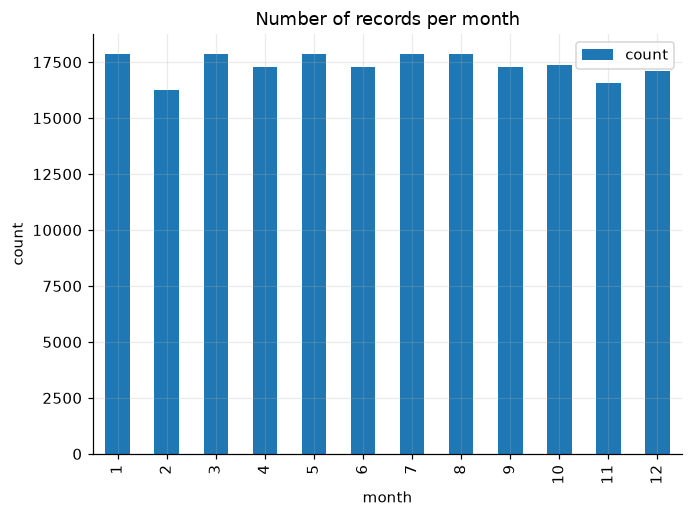

In [8]:
# Number of records per month

df.index.month.value_counts().sort_index().rename("count").to_frame().plot.bar(title="Number of records per month", ylabel="count", xlabel="month")
plt.tight_layout()
plt.show()

### 1.5 yearly Data Distribution 

Partial years: {2026: 77.8}


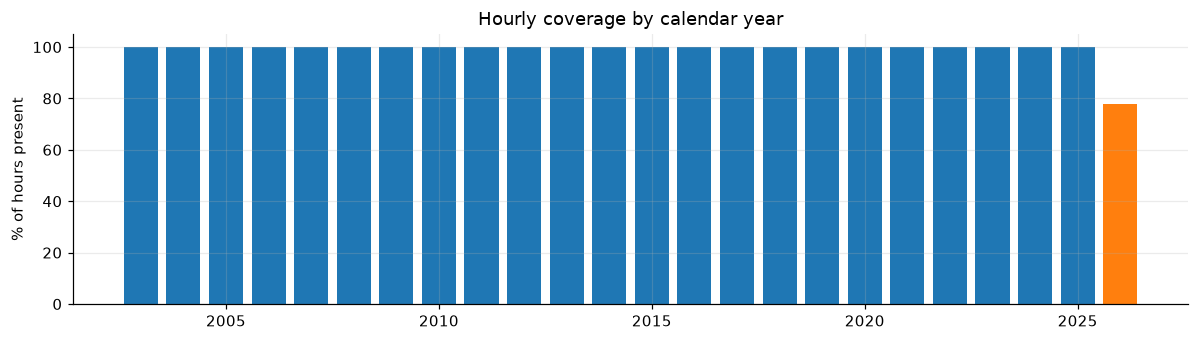

In [16]:
# Year included in the dataframe
observed = df.groupby(df.index.year).size()

# Expected Hours in a Year
expected = pd.Series({y: audit.expected_hours_in_year(y) for y in observed.index})

# Coverage Percentage
coverage = observed / expected * 100

print(f"Partial years: {coverage[coverage < 100].round(1).to_dict()}")

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(coverage.index, coverage.values,
       color=np.where(coverage < 100, "tab:orange", "tab:blue"))
ax.set(ylim=(0, 105), ylabel="% of hours present", title="Hourly coverage by calendar year")
plt.show()


### Observations
- **Shape:** 208,440 hourly rows from 2003-01-01 00:00 to 2026-10-11 23:00 (23.8 years), index is a naive `datetime64`, six numeric columns.

- **Integrity:** no duplicate timestamps, strictly increasing, every step exactly one hour, row count equals the span. No NaNs and none of the sentinel codes.

- **Coverage:** every calendar year is 100 % complete except **2026 (77.8 %)**, simply because the record stops on 11 October.

- **Resolution:** humidity and wind direction are stored as whole numbers (1 % and 1°); temperature, pressure, wind speed and rain at 0.1.

### Conclusion
- ✅ Structure passes every check. **No imputation or gap handling is needed for the weather series.**

- The file is a *superset* of what we need: it will be trimmed to the PM2.5 station overlap at join time (the long history is still useful for climatology, step 7).

- 2026 is partial, so calendar-year means for 2026 must not be compared with full years (handled in step 7).

---

# Step 2  Ranges, units and suspicious values

**What we are looking for.** 

Range checks catch unit mix-ups, sentinel codes and sensor faults. A flag is a **question, not a verdict**:
we ask whether a value is *physically possible for Delhi*, and whether flagged values cluster in time (a fault) or in a season (a climate feature).
We use broad *review* ranges and never clip or delete on a range alone.

**Checks:** each variable inside a plausible range · humidity of exactly 100 % · wind direction at zero wind speed (direction is undefined when there is no wind) · how north is encoded (0 or 360) · when and where the extremes occur.

### 2.1 Data description 

In [19]:
# DataFrame Description 
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
temperature_2m,208440.0,24.682,8.090,1.9,18.7,26.1,30.3,46.5
relative_humidity_2m,208440.0,61.626,23.596,4.0,43.0,64.0,82.0,100.0
rain,208440.0,0.079,0.480,0.0,0.0,0.0,0.0,24.2
wind_speed_10m,208440.0,9.074,4.449,0.0,6.1,8.4,11.3,37.6
wind_direction_10m,208440.0,215.615,104.868,1.0,114.0,267.0,304.0,360.0
surface_pressure,208440.0,983.049,6.643,964.7,977.4,983.2,988.8,1001.0


### 2.1 Daily Overview of all Variables 

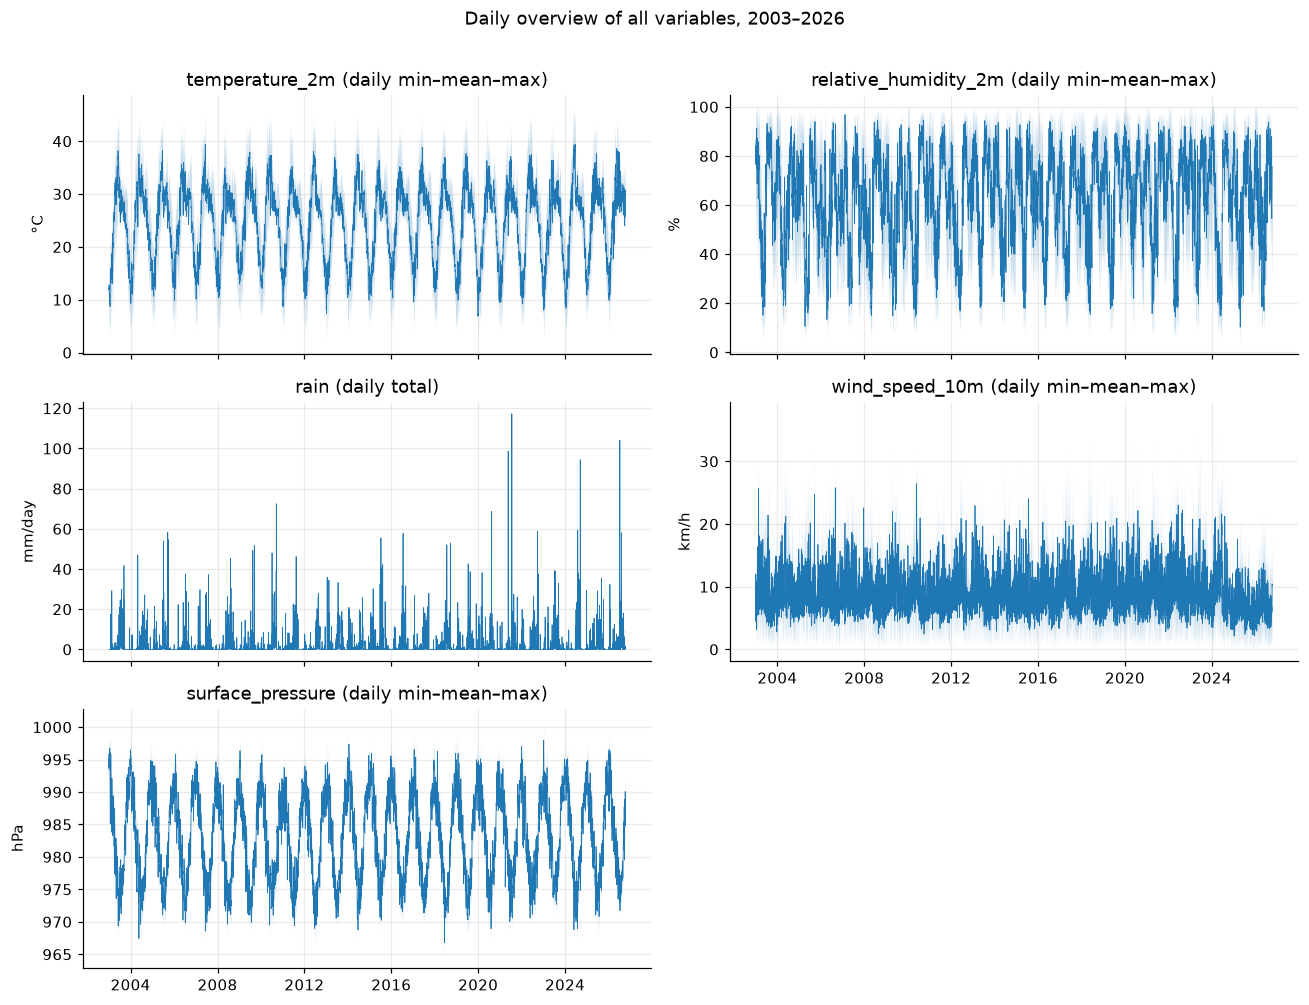

In [11]:
# Daily Overview of all Variables 
daily = df.resample("D").agg(["min", "mean", "max"])

# All variables
panels = ["temperature_2m", "relative_humidity_2m", "rain", "wind_speed_10m", "surface_pressure"]

fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)


for ax, col in zip(axes.flat, panels):
    
    if col == "rain":
        ax.plot(df["rain"].resample("D").sum(), lw=0.5, color="tab:blue")
        ax.set_title("rain (daily total)")
        ax.set_ylabel("mm/day")
    else:
        ax.fill_between(daily.index, daily[col]["min"], daily[col]["max"],
                        alpha=0.25, color="tab:blue", lw=0)
        ax.plot(daily[col]["mean"], lw=0.5, color="tab:blue")
        ax.set_title(f"{col} (daily min–mean–max)")
        ax.set_ylabel(UNITS[col])
        
axes.flat[-1].axis("off")
axes[1, 1].tick_params(labelbottom=True)


fig.suptitle("Daily overview of all variables, 2003–2026", y=1.01)
plt.show()

### 2.2 Yearly plot for all variables 

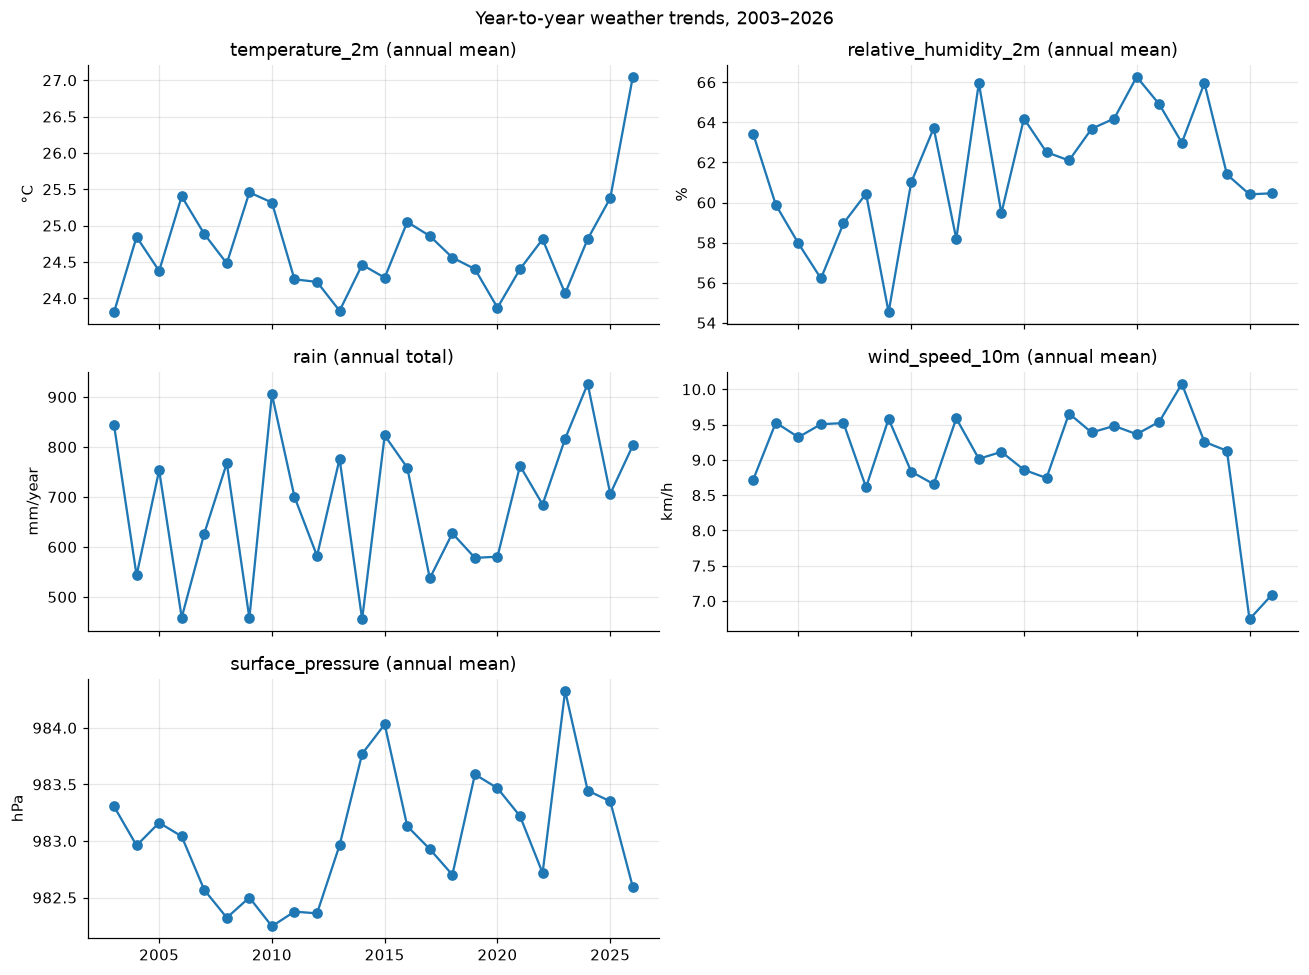

In [ ]:
yearly = df[panels].resample("YS").agg({
    "temperature_2m": "mean",
    "relative_humidity_2m": "mean",
    "rain": "sum",
    "wind_speed_10m": "mean",
    "surface_pressure": "mean",
})

fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)

for ax, col in zip(axes.flat, panels):
    ax.plot(yearly.index.year, yearly[col], marker="o", lw=1.5)
    ax.set_title(f"{col} ({'annual total' if col == 'rain' else 'annual mean'})")
    ax.set_ylabel("mm/year" if col == "rain" else UNITS[col])
    ax.grid(True, alpha=0.3)

axes.flat[-1].axis("off")
fig.suptitle("Year-to-year weather trends, 2003–2026")
fig.tight_layout()
plt.show()

### 2.3 Range Audit 

In [ ]:
REVIEW_RANGES = {
    "temperature_2m": (-5, 50),
    "relative_humidity_2m": (0, 100),
    "rain": (0, None),
    "wind_speed_10m": (0, None),
    "wind_direction_10m": (0, 360),
    "surface_pressure": (970, 1010),   # station Level not sea level 
}

audit.range_violations(df, REVIEW_RANGES)

,review_range,below,above,min,max
variable,,,,,
temperature_2m,-5 to 50,0,0,1.9,46.5
relative_humidity_2m,0 to 100,0,0,4.0,100.0
rain,0 to None,0,0,0.0,24.2
wind_speed_10m,0 to None,0,0,0.0,37.6
wind_direction_10m,0 to 360,0,0,1.0,360.0
surface_pressure,970 to 1010,1409,0,964.7,1001.0


### 2.4 Check for Outliers

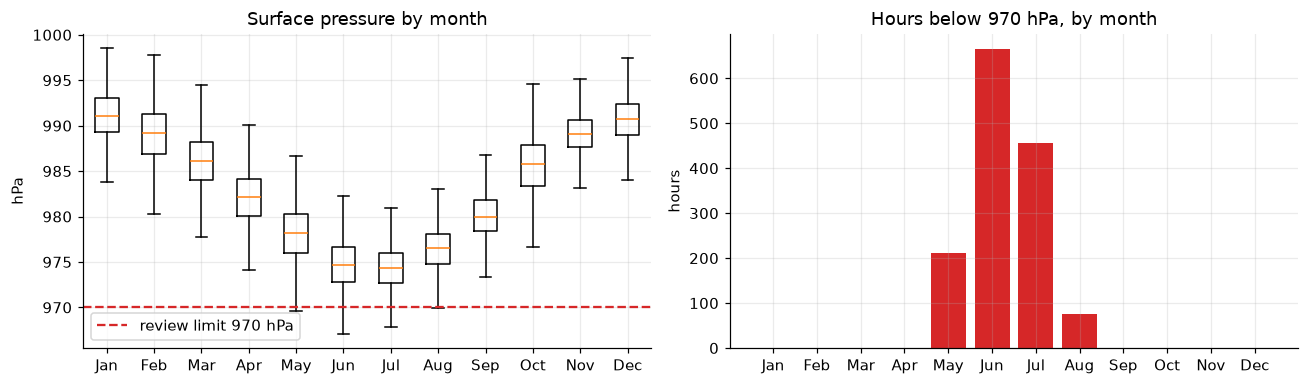

Years with flagged hours: 22 of 24
Lowest value: 964.7 hPa on 2018-06-12 17:00:00


In [ ]:
# 1,409 hours are below the pressure review range. Are they errors or climate?

low_pressure = df[df["surface_pressure"] < 970]

by_month = (low_pressure.groupby(low_pressure.index.month).size().reindex(range(1, 13), fill_value=0))
by_month.index = audit.MONTH_LABELS

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))

ax1.boxplot([df.loc[df.index.month == m, "surface_pressure"] for m in range(1, 13)],
            tick_labels=audit.MONTH_LABELS, showfliers=False)
ax1.axhline(970, color="tab:red", ls="--", label="review limit 970 hPa")
ax1.set(ylabel="hPa", title="Surface pressure by month")
ax1.legend()


ax2.bar(by_month.index, by_month.values, color="tab:red")
ax2.set(ylabel="hours", title="Hours below 970 hPa, by month")
plt.show()

print("Years with flagged hours:", low_pressure.index.year.nunique(), "of", df.index.year.nunique())
print("Lowest value:", low_pressure["surface_pressure"].min(), "hPa on",
      low_pressure["surface_pressure"].idxmin())

Atmospheric pressure decreases with altitude. Delhi sits at roughly 216 meters above sea level. Because of this elevation, the surface pressure in Delhi is typically around 970 hPa, with a normal range between roughly 959 hPa and 979 hPa.

The value found 964.7 hPa exactly matches the minimum station pressure recorded for June in Delhi according to historical climate data. This confirms that  Open-Meteo extraction is capturing surface pressure, which is naturally lower than the standard sea-level pressure readings (often around 1000 hPa) that are more commonly reported in weather forecasts

### Observation :

- **Dust Storm and Haze:** On June 12, 2018, a ground-level dust storm hit neighboring Rajasthan, which significantly increased coarse particulate matter (PM10) in the air across Delhi and the National Capital Region. This led to hazy conditions and a sharp dip in air quality, with PM10 levels at several monitoring stations exceeding 900 μg/m³.

- **Anti-Cyclonic Winds:** The India Meteorological Department (IMD) attributed the dusty conditions to anti-cyclonic winds blowing from Rajasthan across Delhi-NCR and western Uttar Pradesh, with wind speeds reaching around 40 km/h.

- **Broader Low-Pressure Pattern:** The stormy pre-monsoon season of 2018 was influenced by a combination of Western Disturbances and a low-pressure area over the Indo-Gangetic plains, which, along with intense heating, contributed to frequent dust storms in the region.

-  **Cause of the Dust:** A western disturbance combined with intense pre-monsoon heat over Rajasthan generated strong winds that lifted vast quantities of dust. As these winds reached Delhi, the dust became suspended in the atmosphere, creating a thick, hazy blanket over the city.

- **Pressure Connection:** The dust storm was associated with a low-pressure area (or a trough) over Northwest India. This low-pressure system helped draw the dust-laden winds into Delhi and likely contributed to the pressure dropping to the lower end of its normal range at your location.



### 2.5 Revision for Surface Pressure

In [33]:
# Revised range after investigation, then re-check.
REVIEW_RANGES["surface_pressure"] = (960, 1010)
audit.range_violations(df, REVIEW_RANGES)

,review_range,below,above,min,max
variable,,,,,
temperature_2m,-5 to 50,0,0,1.9,46.5
relative_humidity_2m,0 to 100,0,0,4.0,100.0
rain,0 to None,0,0,0.0,24.2
wind_speed_10m,0 to None,0,0,0.0,37.6
wind_direction_10m,0 to 360,0,0,1.0,360.0
surface_pressure,960 to 1010,0,0,964.7,1001.0


### 2.6 Outliers for other variables 

In [13]:
# Other flags worth checking.

humidity_100 = df[df["relative_humidity_2m"] == 100]
calm = df[df["wind_speed_10m"] == 0]
direction = df["wind_direction_10m"]

print(f"RH exactly 100%: {len(humidity_100)} hours ({len(humidity_100) / len(df):.2%})")
print("  by month:", humidity_100.groupby(humidity_100.index.month).size().to_dict(),"\n")


print(f"Calm hours (speed == 0): {len(calm)}")
print("  direction stored for those hours:", calm["wind_direction_10m"].value_counts().to_dict(),"\n")
print()

print(f"Direction min/max: {direction.min()} / {direction.max()}")
print(f"  hours stored as 360: {(direction == 360).sum()}   hours stored as 0: {(direction == 0).sum()}","\n")


extremes = pd.DataFrame({"max": df[VARS].max(), "when max": df[VARS].idxmax(),
                        "min": df[VARS].min(), "when min": df[VARS].idxmin()})
display(extremes)

RH exactly 100%: 531 hours (0.25%)
  by month: {1: 309, 2: 84, 3: 30, 7: 1, 9: 10, 10: 6, 11: 4, 12: 87} 

Calm hours (speed == 0): 54
  direction stored for those hours: {270: 54} 


Direction min/max: 1 / 360
  hours stored as 360: 1384   hours stored as 0: 0 



,max,when max,min,when min
temperature_2m,46.5,2024-05-30 14:00:00,1.9,2013-01-06 07:00:00
relative_humidity_2m,100.0,2003-01-07 02:00:00,4.0,2003-05-03 13:00:00
rain,24.2,2023-07-20 18:00:00,0.0,2003-01-01 00:00:00
wind_speed_10m,37.6,2024-03-24 15:00:00,0.0,2003-02-23 13:00:00
wind_direction_10m,360.0,2003-01-01 05:00:00,1.0,2003-09-11 13:00:00
surface_pressure,1001.0,2023-01-06 10:00:00,964.7,2018-06-12 17:00:00


### Observations

- **Everything is in range except pressure.** 

The first review range (970–1010 hPa) flagged **1,409 hours**. They are not errors: all fall between **May and September** (665 in June, 456 in July, 212 in May, 75 in August, 1 in September) and occur in 22 of the 24 years. That is the pre-monsoon *heat low* over north-west India;

monthly mean pressure drops from ~990 hPa in winter to ~974 hPa in June–July. The lowest value is 964.7 hPa (2018-06-12 17:00). The review range was too tight, so it is revised to **960–1010 hPa**, which flags nothing.


- **Extremes are plausible for Delhi:** 46.5 °C on 2024-05-30 14:00 and 1.9 °C on 2013-01-06 07:00; humidity 4 % (2003-05-03, a hot dry afternoon) to 100 %; heaviest rain 24.2 mm in one hour (2023-07-20, monsoon); strongest wind 37.6 km/h (2024-03-24).

- **Humidity exactly 100 %:** 531 hours (0.25 %), and **480 of them (90 %) are in December–February**, i.e. winter fog nights. That is real saturation, not a cap artefact.

- **Calm hours:** 54 hours with wind speed 0, and the stored direction is **270° in all 54**. That is a placeholder, not a measurement.

- **North is encoded as 360, never 0:** 1,384 hours are stored as 360 and none as 0. Any code that filters directions to `0 ≤ d < 360` silently drops every northerly hour (this was a bug in my earlier wind-rose function).

### Conclusion / decisions

- **D3 — No clipping and no deletion.** Every flag was explained by climate. Review range for pressure is revised to 960–1010 hPa.
- **D4 — Wind direction is never used as raw degrees.** Convert speed + direction to **u/v components**; use `direction % 360` wherever direction is needed; calm hours get u = v = 0 (the stored 270° is ignored).
- Note  that a ~10 km grid cell smooths extremes, so these values will understate the extremes a street-level sensor would record.

---
# Step 3  Flat-lines and constant runs

**What we are looking for.** 

A stuck sensor, or a gap forward-filled by the provider, shows up as many consecutive identical values.
For a continuous variable measured to 0.1 units (temperature, pressure, wind) a run of more than a few hours should be essentially impossible.

**The exception is rain.** It is zero most of the time, so long runs of `0.0` are *normal*; a flat-line test on rain only produces false alarms.
For rain the useful question is different: **how long are the dry spells, and when do they happen?**

In [14]:
non_rain = [c for c in VARS if c != "rain"]
runs = pd.DataFrame({
    col: {
        "runs of >= 24 h": len(audit.constant_runs(df[col], 24)),
        "longest identical run (h)": audit.constant_runs(df[col], 2)["hours"].max(),
    }
    for col in non_rain
}).T
display(runs)


,runs of >= 24 h,longest identical run (h)
temperature_2m,0,6
relative_humidity_2m,0,9
wind_speed_10m,0,7
wind_direction_10m,0,6
surface_pressure,0,6


In [37]:
display(audit.constant_runs(df["relative_humidity_2m"], 6).head(3))

,value,start,end,hours
0,96,2024-12-28 21:00:00,2024-12-29 05:00:00,9
1,98,2014-12-16 00:00:00,2014-12-16 07:00:00,8
2,100,2026-01-31 00:00:00,2026-01-31 07:00:00,8


Non-zero rain values inside 24h+ runs: 0


,start,end,hours,days
0,2016-10-05 17:00:00,2017-01-06 13:00:00,2229,92.9
1,2024-10-06 16:00:00,2024-12-08 20:00:00,1517,63.2
2,2022-03-03 16:00:00,2022-05-04 17:00:00,1490,62.1
3,2004-01-31 16:00:00,2004-04-02 14:00:00,1487,62.0
4,2025-10-31 13:00:00,2026-01-01 05:00:00,1481,61.7
5,2011-10-08 17:00:00,2011-12-09 02:00:00,1474,61.4
6,2006-01-03 05:00:00,2006-02-26 14:00:00,1306,54.4
7,2003-09-24 14:00:00,2003-11-17 04:00:00,1287,53.6
8,2017-09-23 18:00:00,2017-11-15 13:00:00,1268,52.8
9,2020-09-24 07:00:00,2020-11-15 15:00:00,1257,52.4


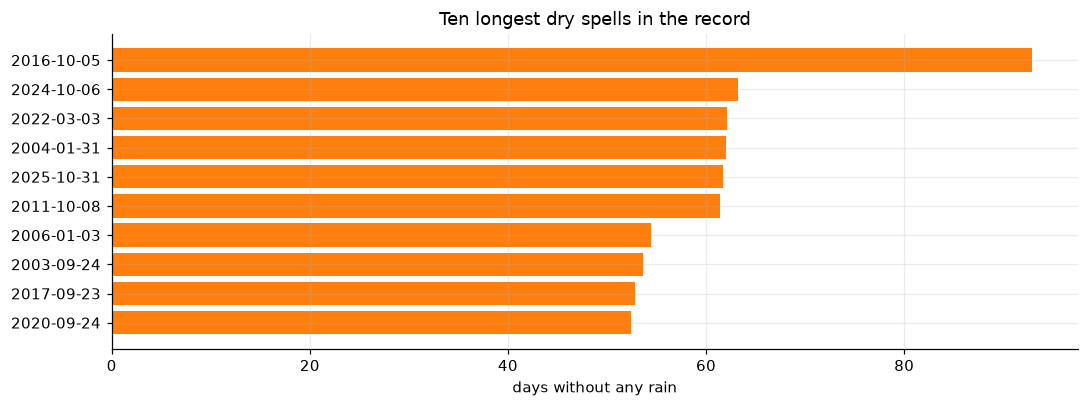

Dry spells (>= 24 h) by start month: {'Jan': 69, 'Feb': 77, 'Mar': 90, 'Apr': 99, 'May': 132, 'Jun': 117, 'Jul': 90, 'Aug': 85, 'Sep': 98, 'Oct': 60, 'Nov': 37, 'Dec': 41}


In [ ]:
dry = audit.constant_runs(df["rain"], 24)
print("Non-zero rain values inside 24h+ runs:", int((dry["value"] != 0).sum()))


dry = dry.assign(days=(dry["hours"] / 24).round(1))
display(dry.head(10)[["start", "end", "hours", "days"]])

top = dry.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(top["start"].dt.strftime("%Y-%m-%d"), top["days"], color="tab:orange")
ax.set(xlabel="days without any rain", title="Ten longest dry spells in the record")
plt.show()

start_month = dry["start"].dt.month.value_counts().reindex(range(1, 13), fill_value=0)
print("Dry spells (>= 24 h) by start month:", dict(zip(audit.MONTH_LABELS, start_month)))

### Observations
- **No stuck or filled data.** For temperature, humidity, wind speed, wind direction and pressure there are **zero** runs of 24 or more identical hourly values. The longest identical run is 6 h (temperature, direction, pressure), 7 h (wind speed) and 9 h for humidity (96 % on a December 2024 night).

- **Rain:** 995 dry spells of 24 h or more, all exactly 0.0 mm (not a single non-zero value inside a long run). The longest is **2,229 hours = 92.9 days (2016-10-05 to 2017-01-06)**; the ten longest range from 52 to 93 days.

- **Timing:** **seven of the ten longest dry spells start between 23 September and 31 October**, right as the monsoon withdraws. So a rain-free stretch of two to three months inside the stubble-burning / winter-smog window is entirely possible, and only 1–2 % of hours are wet in November–December (step 6).

### Conclusion / decisions
- ✅ No evidence of stuck sensors or forward-filled gaps in the weather series.
- **D5 — Rain is handled differently from every other variable.** Exclude it from flat-line checks; model it as a **wet/dry flag plus an amount**, and add rolling totals (24 h / 72 h) and **hours since last rain** as features. The dry-spell length is likely informative for PM2.5, because nothing washes particles out.

---
## Step 4 · Distributions

**What we are looking for.** The shape of each variable decides how it must be modelled:
**skew** (log transforms or tree models), **zero-inflation** (rain is "did it rain?" and "how much?"), **bounded or saturated values** (humidity at 100 %),
and **circular variables** (wind direction wraps at 360°, so averaging it is wrong; it must become *u/v* components).
We also compare mean with median: a large gap means a long tail.

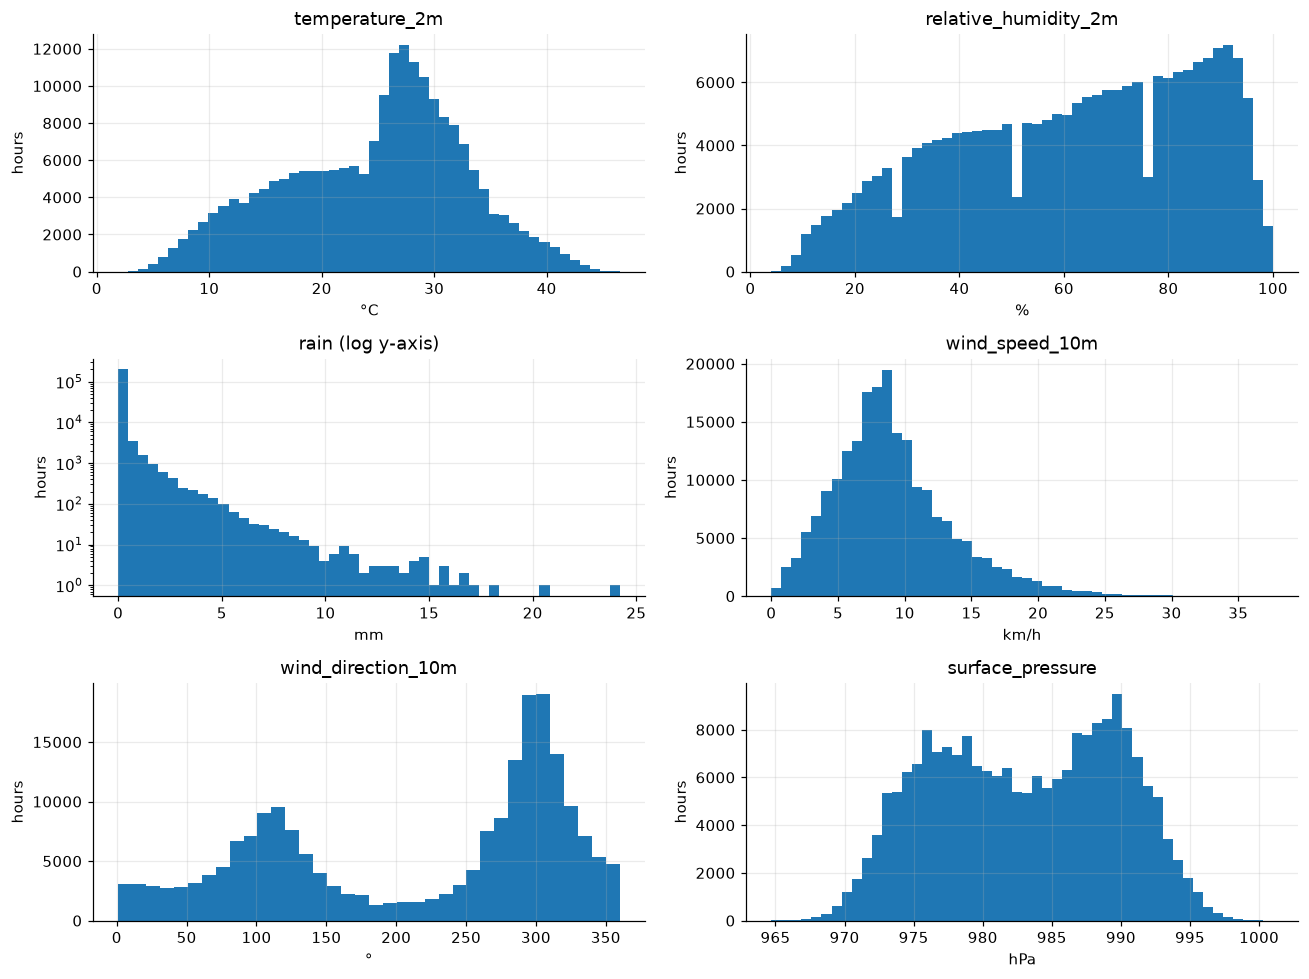

,mean,median,skew
temperature_2m,24.682,26.1,-0.274
relative_humidity_2m,61.626,64.0,-0.326
rain,0.079,0.0,13.233
wind_speed_10m,9.074,8.4,0.949
wind_direction_10m,215.615,267.0,-0.441
surface_pressure,983.049,983.2,-0.059


Hours with rain > 0: 9.59% (19,993 hours)
Rain amount when it rains: median 0.3 mm, 95th pct 3.3 mm


In [44]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9))
for ax, col in zip(axes.flat, VARS):
    ax.hist(df[col], bins=36 if col == "wind_direction_10m" else 50, color="tab:blue")
    ax.set(title=col, xlabel=UNITS[col], ylabel="hours")
    if col == "rain":
        ax.set_yscale("log")
        ax.set_title("rain (log y-axis)")
plt.show()

summary = pd.DataFrame({"mean": df[VARS].mean(), "median": df[VARS].median(),
                        "skew": df[VARS].skew()})
display(summary)
wet = df["rain"] > 0
print(f"Hours with rain > 0: {wet.mean():.2%} ({wet.sum():,} hours)")
print(f"Rain amount when it rains: median {df.loc[wet, 'rain'].median()} mm, "
    f"95th pct {df.loc[wet, 'rain'].quantile(0.95)} mm")

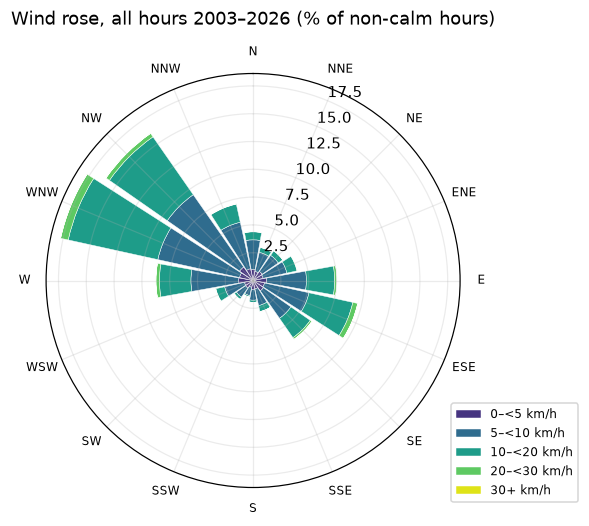

Share of non-calm hours from the W, WNW, NW and NNW sectors: 49.7%


In [46]:
# Wind direction is circular; show the full-record rose (calm hours excluded).
rose = audit.wind_rose_table(df["wind_speed_10m"], df["wind_direction_10m"])

fig = plt.figure(figsize=(5.5, 5.5))

audit.plot_wind_rose(fig.add_subplot(projection="polar"), rose,
                  "Wind rose, all hours 2003–2026 (% of non-calm hours)")

plt.legend(loc="lower right", bbox_to_anchor=(1.3, -0.05), fontsize=8)
plt.show()


print("Share of non-calm hours from the W, WNW, NW and NNW sectors:",
      f"{rose.loc[['W', 'WNW', 'NW', 'NNW']].to_numpy().sum():.1f}%")

### Observations
- **Rain is extremely zero-inflated and skewed** (skew 13.2): it rains in only **9.6 % of hours** (19,993 h), and when it does the median is 0.3 mm/h (95th percentile 3.3 mm/h). The mean (0.08 mm) is meaningless as a summary.

- **Wind speed is right-skewed** (skew +0.95; mean 9.1 > median 8.4 km/h; maximum 37.6).

- **Temperature, humidity and pressure** are close to symmetric (|skew| ≤ 0.33). Humidity covers the whole 4–100 % range; temperature and pressure are broad because they mix very different seasons.

- **Wind direction is strongly directional:** over the full record, **49.7 % of non-calm hours blow from W–NNW** (W, WNW, NW, NNW sectors), with a secondary easterly lobe. Averaging directions would be meaningless.

### Conclusion / decisions
- Tree models cope with all of these shapes as they are; the **ridge baseline needs the transformations**: u/v for wind (D4), a wet flag + log-scaled amount for rain (D5).
- The north-westerly dominance is the first sign that **direction is informative** and that a fire-region feature (Punjab/Haryana lies NW of Delhi) is geometrically sensible.

---
## Step 5 · Timezone proof

**What we are looking for.** The file says `Asia/Kolkata`, but a label is a claim, not evidence. Physics gives an independent clock:
near-surface temperature peaks in the **mid-afternoon (~14:00–16:00 local)** and bottoms out around **sunrise (~06:00–07:00)**.
If the labelled times were really UTC, the apparent peak would sit ~5.5 h earlier (≈ 08:30–10:30).
This matters because the PM2.5 stations report in IST: a silent 5.5-hour shift between weather and pollution would quietly destroy every lag and diurnal feature.

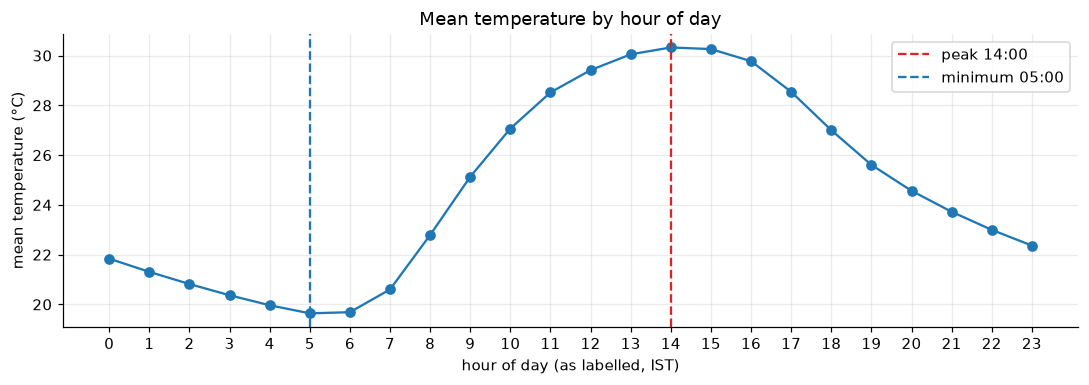

,peak hour,coolest hour
season,,
Winter,14,7
Pre-monsoon,14,5
Monsoon,14,5
Post-monsoon,14,6


In [47]:
cal = audit.add_calendar(df)

by_hour = df["temperature_2m"].groupby(df.index.hour).mean()
peak, trough = int(by_hour.idxmax()), int(by_hour.idxmin())

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(by_hour.index, by_hour.values, marker="o")
ax.axvline(peak, color="tab:red", ls="--", label=f"peak {peak:02d}:00")
ax.axvline(trough, color="tab:blue", ls="--", label=f"minimum {trough:02d}:00")
ax.set(xticks=range(0, 24), xlabel="hour of day (as labelled, IST)",
       ylabel="mean temperature (°C)", title="Mean temperature by hour of day")

ax.legend()
plt.show()

per_season = (cal.groupby(["season", "hour"], observed=True)["temperature_2m"].mean().unstack("hour"))
display(pd.DataFrame({"peak hour": per_season.idxmax(axis=1),
                     "coolest hour": per_season.idxmin(axis=1)}))

### Observations
- Mean temperature **peaks at 14:00 IST** (a 14:00–15:00 plateau at ~30.3 °C) and is **lowest at 05:00** (19.6 °C).

- The pattern holds in **every season**: the peak is at 14:00 in winter, pre-monsoon, monsoon and post-monsoon, and the coolest hour moves with sunrise (07:00 in winter, 06:00 post-monsoon, 05:00 in summer and monsoon).

- If the labels were actually UTC, the apparent peak would sit around 08:30–09:30; nothing like that appears.

### Conclusion / decision
- **D2 — The timestamps are local IST; no shift is applied.** Keep the series as naive IST, but make the zone explicit in the cleaning step (`tz_localize("Asia/Kolkata")`; India has no daylight saving, so there is no ambiguity). CPCB is also IST, so that join needs no conversion; **FIRMS fire data is UTC and must be converted at its join**.
- Reanalysis peaks a little earlier than a thermometer in the shade typically does (often 15:00–16:00), which is normal for a gridded product and not a labelling error.

---
## Step 6 · Seasonality

**What we are looking for.** Delhi has four regimes that behave like different datasets: winter (cold, humid, foggy nights), pre-monsoon (hot, dry, dusty),
monsoon (rain, humid) and post-monsoon (stubble-burning season). Seasonality tells us which periods the model must be evaluated on *separately*,
and gives a sanity check against lived experience: if the monthly pattern does not match what you know of Delhi, something is wrong with the data.

**Checks:** monthly distributions · share of hours with rain per month · diurnal cycle per season.

,temp median °C,RH median %,hours with rain %,mean wind km/h
Jan,12.8,79.0,4.6,8.6
Feb,16.5,69.0,4.9,9.5
Mar,22.0,54.0,4.0,9.8
Apr,28.7,31.0,2.6,10.3
May,31.9,34.0,3.4,10.2
Jun,32.6,49.0,9.7,10.5
Jul,29.3,79.0,30.4,9.1
Aug,28.4,82.0,31.0,8.8
Sep,27.7,78.0,17.9,8.5
Oct,25.4,62.0,2.4,7.5


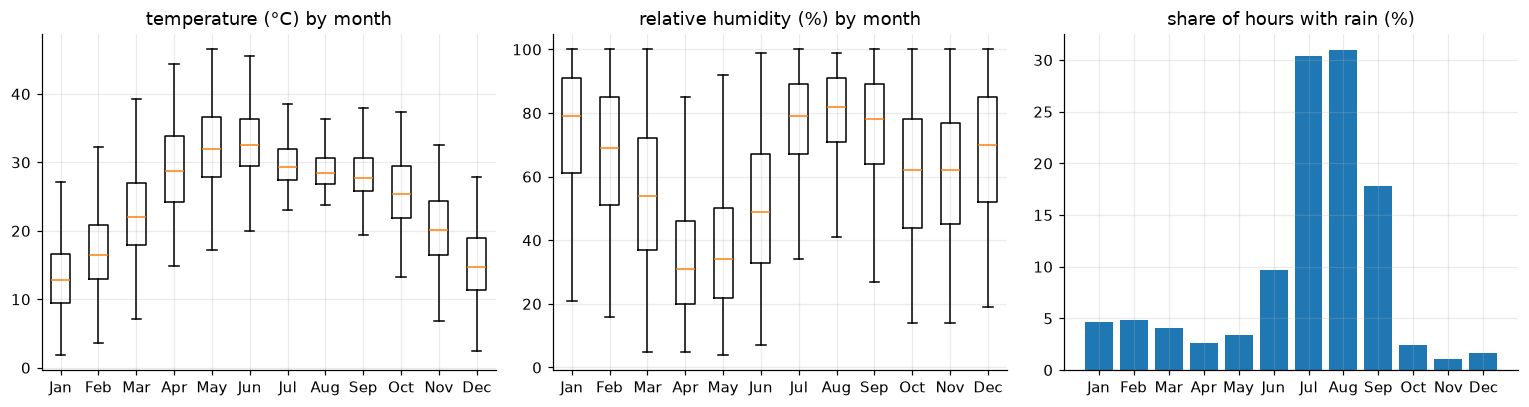

In [48]:
monthly = pd.DataFrame({
    "temp median °C": cal.groupby("month")["temperature_2m"].median(),
    "RH median %": cal.groupby("month")["relative_humidity_2m"].median(),
    "hours with rain %": cal.groupby("month")["rain"].apply(lambda s: s.gt(0).mean() * 100),
    "mean wind km/h": cal.groupby("month")["wind_speed_10m"].mean(),
})
monthly.index = audit.MONTH_LABELS
display(monthly.round(1))


fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, label in [(axes[0], "temperature_2m", "temperature (°C)"),
                    (axes[1], "relative_humidity_2m", "relative humidity (%)")]:
    ax.boxplot([cal.loc[cal["month"] == m, col] for m in range(1, 13)],
            tick_labels=audit.MONTH_LABELS, showfliers=False)
    ax.set(title=f"{label} by month")


axes[2].bar(audit.MONTH_LABELS, monthly["hours with rain %"], color="tab:blue")
axes[2].set(title="share of hours with rain (%)")
plt.tight_layout()
plt.show()

In [51]:
display(cal)

,temperature_2m,relative_humidity_2m,rain,wind_speed_10m,wind_direction_10m,surface_pressure,month,hour,season,season_year
time,,,,,,,,,,
2003-01-01 00:00:00,9.5,94,0.0,10.9,314,990.2,1,0,Winter,2003
2003-01-01 01:00:00,9.3,94,0.0,10.5,319,990.6,1,1,Winter,2003
2003-01-01 02:00:00,9.2,94,0.0,9.1,326,991.0,1,2,Winter,2003
2003-01-01 03:00:00,9.1,94,0.0,7.3,327,991.5,1,3,Winter,2003
2003-01-01 04:00:00,9.2,94,0.0,6.6,338,991.9,1,4,Winter,2003
...,...,...,...,...,...,...,...,...,...,...
2026-10-11 19:00:00,23.0,76,0.1,9.3,46,991.4,10,19,Post-monsoon,2026
2026-10-11 20:00:00,23.1,73,0.0,9.3,82,991.3,10,20,Post-monsoon,2026
2026-10-11 21:00:00,23.0,73,0.0,5.8,85,991.3,10,21,Post-monsoon,2026


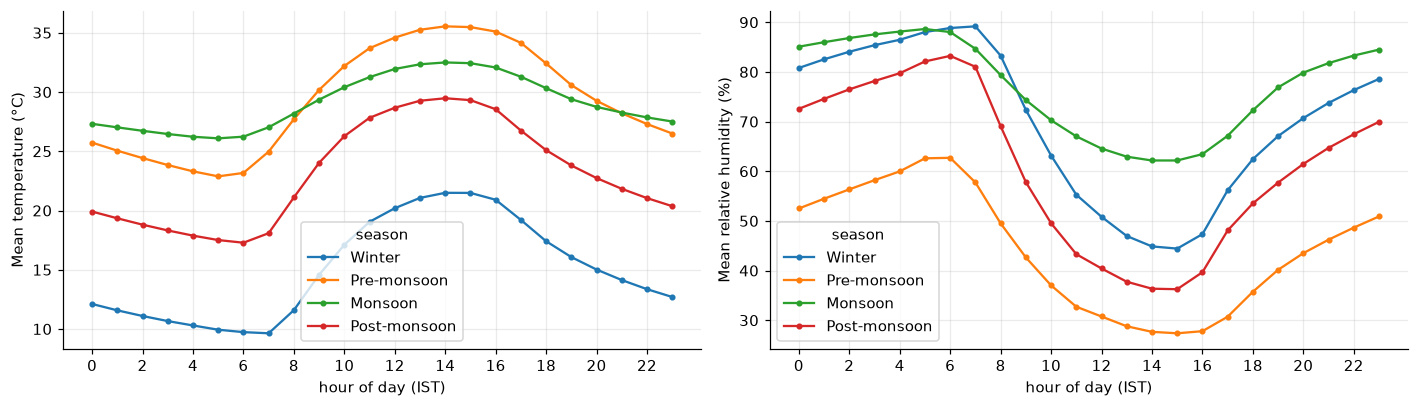

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)

for ax, col, label in [(axes[0], "temperature_2m", "Mean temperature (°C)"), (axes[1], "relative_humidity_2m", "Mean relative humidity (%)")]:
    profile = cal.groupby(["season", "hour"], observed=True)[col].mean().unstack("season")
    profile.plot(ax=ax, marker="o", ms=3)
    ax.set(xticks=range(0, 24, 2), xlabel="hour of day (IST)", ylabel=label)
plt.show()

### Observations
- **Temperature:** monthly median rises from 12.8 °C (Jan) to **32.6 °C (Jun)** and falls to 14.7 °C by December; April–June is the hot, dry period.

- **Humidity:** median RH is lowest in **April–May (31–34 %)** and highest in **July–August (79–82 %)**; winter nights are humid (see the diurnal panel: RH peaks around 06:00–07:00 in winter, reaching ~89 %, and bottoms out at 14:00–15:00 in every season).

- **Rain:** 30–31 % of hours are wet in **July and August**, 17.9 % in September, 9.7 % in June, and **no more than 5 % of hours in any of the other months** (October 2.4 %, November 1.1 %, December 1.7 %).

- **Wind:** monthly mean 7.5–10.5 km/h; lowest in October–November (7.5–7.8), highest in April–June (10.2–10.5).
- This matches the known Delhi year: hot dry spring, monsoon July–September, cold foggy December–January.

### Conclusion / decision
- **D7 — Use the four local seasons** (Winter Dec–Feb, Pre-monsoon Mar–Jun, Monsoon Jul–Sep, Post-monsoon Oct–Nov). This differs from the standard IMD calendar on purpose (Delhi's monsoon arrives around the end of June, and the Oct–Nov stubble window is its own regime). The **same mapping must be reused for the PM2.5 analysis** so regimes line up.
- Regime-wise evaluation is justified: these seasons behave like four different datasets.

---
## Step 7 · Year-to-year stability (drift and breaks)

**What we are looking for.** A model learns from the past and is judged on the future, so it assumes the data-generating process is stable.
A **level shift** in one variable (an instrument change, a model or source switch) is a *covariate shift that has nothing to do with weather*,
and walk-forward validation would silently measure it as "forecast skill" or "forecast failure".

**Method:** compare years, but **like for like** (partial years bias calendar means; winter spans December to February, so December belongs to the *following* season-year).
Then remove the normal annual cycle (a daily climatology fitted on 2003–2023 only) and look at the *anomaly*, where a step change stands out.

In [60]:
mean_vars = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "surface_pressure"]

annual = df[mean_vars + ["rain"]].groupby(df.index.year).agg({**{c: "mean" for c in mean_vars}, "rain": "sum"}).rename(columns={"rain": "rain total (mm)"})
display(annual.round(1))



,temperature_2m,relative_humidity_2m,wind_speed_10m,surface_pressure,rain total (mm)
time,,,,,
2003,23.8,63.4,8.7,983.3,844.0
2004,24.8,59.9,9.5,983.0,543.2
2005,24.4,58.0,9.3,983.2,753.5
2006,25.4,56.2,9.5,983.0,458.8
2007,24.9,59.0,9.5,982.6,626.7
2008,24.5,60.4,8.6,982.3,767.7
2009,25.5,54.5,9.6,982.5,457.9
2010,25.3,61.0,8.8,982.2,905.3
2011,24.3,63.7,8.7,982.4,700.3


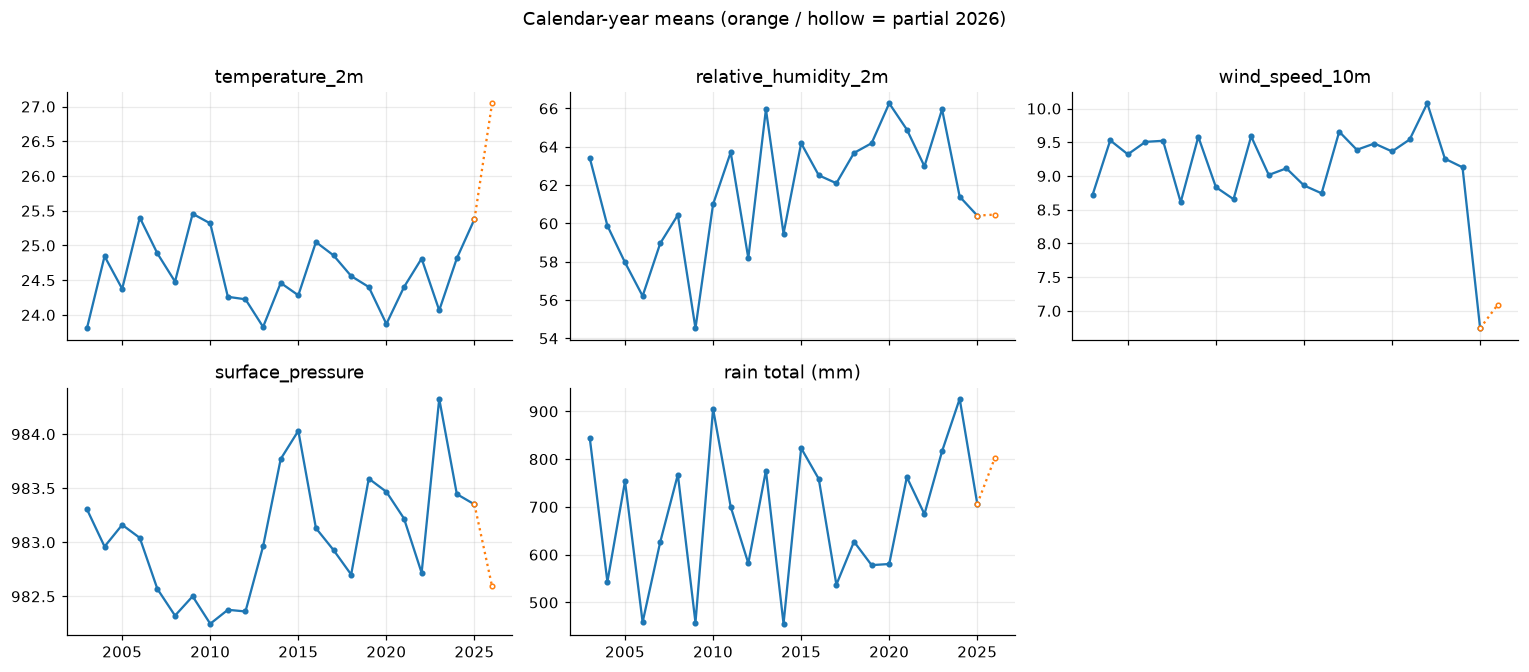

In [62]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)

for ax, col in zip(axes.flat, annual.columns):
    ax.plot(annual.index[:-1], annual[col].iloc[:-1], marker="o", ms=3)
    ax.plot(annual.index[-2:], annual[col].iloc[-2:], ls=":", marker="o", ms=3,
            mfc="white", color="tab:orange")   # 2026 is a partial year
    ax.set_title(col)


axes.flat[-1].axis("off")
fig.suptitle("Calendar-year means (orange / hollow = partial 2026)", y=1.01)
plt.show()

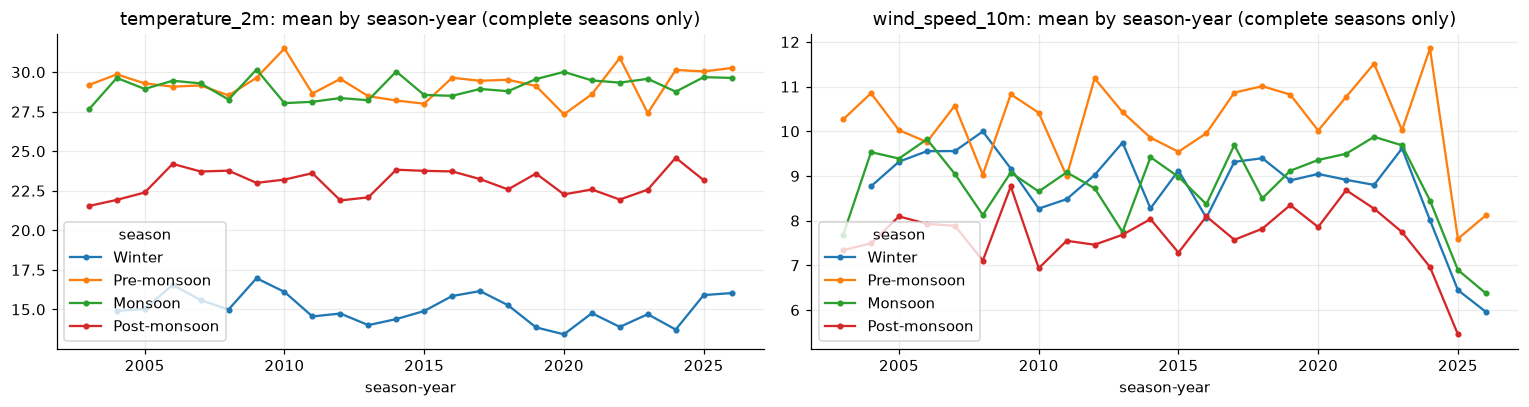

Incomplete seasons dropped: [(2003, 'Winter'), (2026, 'Post-monsoon')]


In [19]:
# Like-for-like: compare seasons, and keep only complete seasons.
cal = audit.add_calendar(df)
counts = cal.groupby(["season_year", "season"], observed=True).size()
complete = counts >= 0.98 * counts.groupby(level="season").transform("max")

seasonal = (cal.groupby(["season_year", "season"], observed=True)
            [["temperature_2m", "wind_speed_10m"]].mean()[complete])

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharex=True)
for ax, col in zip(axes, ["temperature_2m", "wind_speed_10m"]):
    seasonal[col].unstack("season").plot(ax=ax, marker="o", ms=3)
    ax.set(title=f"{col}: mean by season-year (complete seasons only)", xlabel="season-year")
plt.show()
print("Incomplete seasons dropped:", counts[~complete].index.tolist())

In [65]:
# The wind-speed series looks different after 2024. Quantify it.
BASELINE_END = "2023-12-31"
wind_anomaly = audit.daily_anomaly(df["wind_speed_10m"], BASELINE_END)
shift_date, before, after = audit.find_level_shift(wind_anomaly, "2024-06-01", "2025-06-30")
print(f"Best single level shift in daily wind-speed anomaly: {shift_date.date()}")
print(f"Mean anomaly before / after: {before:+.2f} / {after:+.2f} km/h")



Best single level shift in daily wind-speed anomaly: 2024-11-06
Mean anomaly before / after: +0.28 / -2.68 km/h


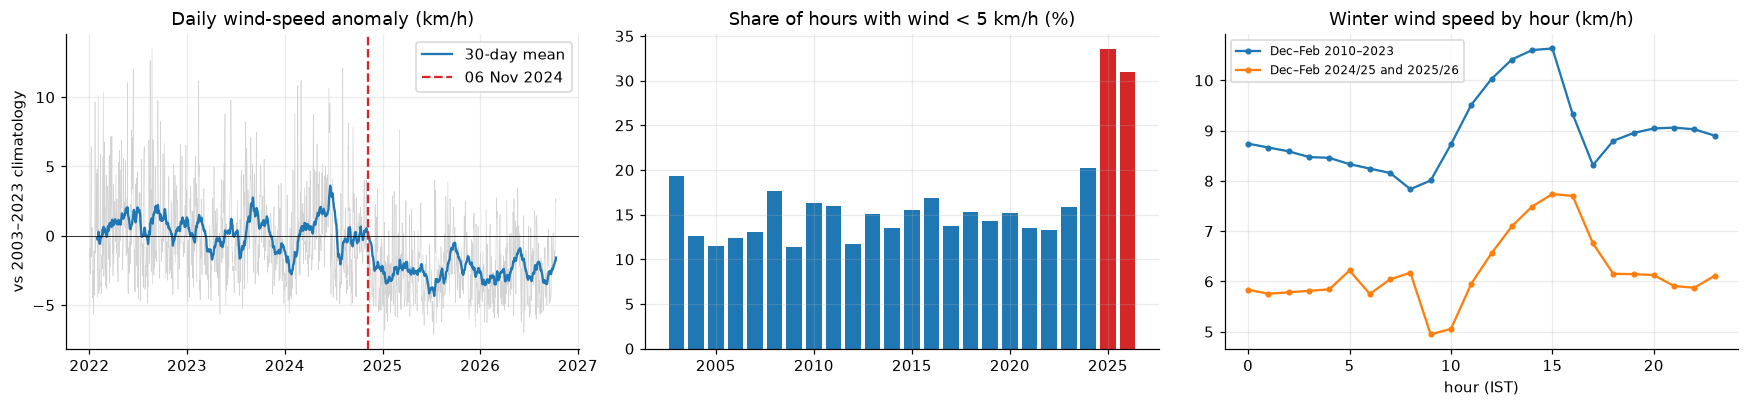

In [66]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))

recent = wind_anomaly.loc["2022-01-01":]
axes[0].plot(recent, lw=0.4, color="lightgray")
axes[0].plot(recent.rolling(30).mean(), color="tab:blue", label="30-day mean")
axes[0].axvline(shift_date, color="tab:red", ls="--", label=shift_date.strftime("%d %b %Y"))
axes[0].axhline(0, color="k", lw=0.5)
axes[0].set(title="Daily wind-speed anomaly (km/h)", ylabel="vs 2003–2023 climatology")
axes[0].legend()

calm_share = (df["wind_speed_10m"] < 5).groupby(df.index.year).mean() * 100
axes[1].bar(calm_share.index, calm_share.values,
            color=np.where(calm_share.index >= 2025, "tab:red", "tab:blue"))
axes[1].set(title="Share of hours with wind < 5 km/h (%)")

winter = df[df.index.month.isin([12, 1, 2])]
for label, part in [("Dec–Feb 2010–2023", winter.loc["2010":"2023-11"]),
                    ("Dec–Feb 2024/25 and 2025/26", winter.loc["2024-12":])]:
    axes[2].plot(part["wind_speed_10m"].groupby(part.index.hour).mean(), marker="o", ms=3, label=label)
axes[2].set(title="Winter wind speed by hour (km/h)", xlabel="hour (IST)")
axes[2].legend(fontsize=8)
plt.show()

In [67]:
# Does any other variable move at the same date? Shift in units of baseline spread.
daily_vars = pd.concat(
    [df[["temperature_2m", "relative_humidity_2m", "surface_pressure", "wind_speed_10m"]],
     audit.wind_components(df["wind_speed_10m"], df["wind_direction_10m"])],
    axis=1,
)
rows = {}
for col in daily_vars:
    anomaly = audit.daily_anomaly(daily_vars[col], BASELINE_END)
    year_before = anomaly.loc[shift_date - pd.Timedelta(days=365): shift_date - pd.Timedelta(days=1)].mean()
    since = anomaly.loc[shift_date:].mean()
    rows[col] = {"mean anomaly, year before": year_before, "mean anomaly, since": since,
                "shift": since - year_before,
                "shift / baseline sd": (since - year_before) / anomaly.loc[:BASELINE_END].std()}


shift_table = pd.DataFrame(rows).T
display(shift_table.round(2))

dtr = df["temperature_2m"].resample("D").agg(lambda s: s.max() - s.min())
print("Mean daily temperature range by year (°C):", dtr.groupby(dtr.index.year).mean().round(1).loc[2022:].to_dict())

,"mean anomaly, year before","mean anomaly, since",shift,shift / baseline sd
temperature_2m,0.06,0.92,0.86,0.41
relative_humidity_2m,1.74,-1.21,-2.95,-0.25
surface_pressure,0.59,0.70,0.11,0.05
wind_speed_10m,0.07,-2.51,-2.58,-0.85
u,-0.04,-0.72,-0.68,-0.10
v,-0.60,0.81,1.40,0.40


Mean daily temperature range by year (°C): {2022: 11.4, 2023: 11.2, 2024: 11.2, 2025: 10.5, 2026: 9.7}


### Observations

- **2003–2024 is stable.** Calendar-year means stay within narrow bands: temperature 23.8–25.5 °C, humidity 54.5–66.3 %, pressure 982.2–984.3 hPa, **wind speed 8.6–10.1 km/h**, rain totals 455–926 mm per year (2003–2025 mean 681 mm).

- **Wind speed falls out of that band in 2025:** annual mean **6.7 km/h (2025)** and 7.1 km/h (2026, partial) against 8.6–10.1 for every earlier year.

- **It is a step, not a trend, and it is in every season.** By season-year, wind speed in 2025 is 6.4 (winter), 7.6 (pre-monsoon), 6.9 (monsoon) and 5.5 km/h (post-monsoon), against 2003–2023 averages of 9.1, 10.3, 9.0 and 7.8.

- **Date:** the best single level shift in the daily wind anomaly is **2024-11-06**: mean anomaly **+0.28 km/h before and −2.68 km/h after**. Over the whole period since, the anomaly averages −2.5 km/h; relative to the year before, that is a shift of −2.6 km/h, or **−0.85 baseline standard deviations**.

- **Consequences visible in the data:** the share of hours with wind < 5 km/h is 11–20 % in every year to 2024, then **33.5 % in 2025 and 30.9 % in 2026**. The winter diurnal wind curve also changes shape (afternoon peak 10.6 → 7.7 km/h; night level ~8.5 → ~5.8 km/h flat).

- **Other variables move much less:** temperature +0.9 °C (+0.4 sd; part of this may be real warming), humidity −3.0 points (−0.25 sd), the north–south wind component +1.4 km/h (+0.4 sd), pressure +0.1 hPa. The **daily temperature range also shrinks**: 11.2 °C in 2023–2024, 10.5 °C in 2025, 9.7 °C in 2026.

### Interpretation (not verified)

A ~30 % drop in wind speed that appears within weeks, in all four seasons, together with a changed diurnal wind shape and a shrinking diurnal temperature range, is far more consistent with a **change in the underlying model or data source** than with climate. This file alone cannot prove that. What it does show is that the series after early November 2024 is **not comparable** with the series before it.

### Conclusion / decisions

- **D6 — Treat the wind-speed series as having a break at ~2024-11-06.** Until resolved, any statistic or model that uses wind speed must not blindly mix the two periods. For descriptive analysis in the next steps we use the **pre-shift period (2003-01-01 to 2024-10-31)**.

- **Why this is urgent:** the proposal's untouched final test season (autumn–winter 2025–26) falls entirely *after* the break. A model trained on pre-break wind and scored on post-break wind would show failures caused by the data source, not by the model.

- **Open item O1:** re-fetch with an explicitly pinned reanalysis model (check the `models` parameter in the Open-Meteo archive docs) and compare. If the shift disappears, pin that model in `fetch_hourly`; if it remains, it is a property of the source and has to be modelled or excluded.

- **D8 — Compare seasons like for like.** Winter is assigned to the season-year of its January (December belongs to the *following* year), and incomplete seasons are dropped (here winter 2003, which lacks December 2002, and post-monsoon 2026).

---
## Step 8 · The pollution-relevant regime (October–February)

**What we are looking for.** PM2.5 builds up when the air is poorly ventilated: **low wind speed** (stagnation), **cold, humid, stable nights** (shallow mixing layer, fog and haze),
and **no rain** (nothing washes particles out). In October–November, smoke from stubble burning in Punjab and Haryana arrives on **north-westerly winds**.
Here we only *describe the weather* in these months. These are hypotheses to test once PM2.5 is joined, not conclusions.

,hours,wind < 5 km/h (%),mean wind km/h,night temp °C (00–05),night RH % (00–05),hours with rain (%)
Oct,16368,19.8,7.6,21.0,77.5,2.2
Nov,15120,17.5,8.0,15.9,77.5,1.2
Dec,15624,15.3,8.5,10.9,83.4,1.6
Jan,16368,12.2,8.9,9.2,88.4,4.8
Feb,14928,10.9,9.7,12.5,82.1,5.1


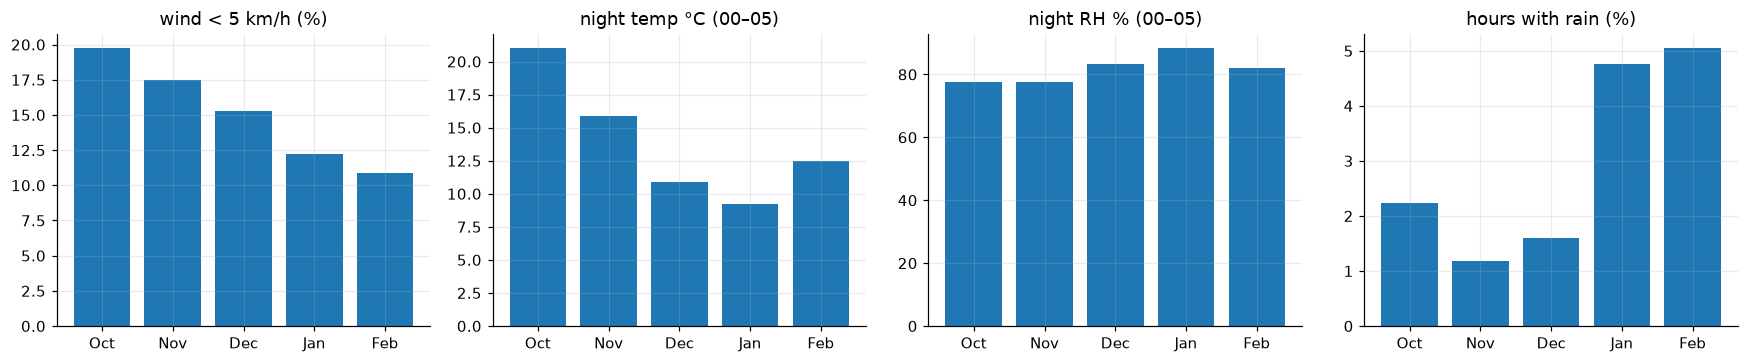

In [69]:
CLEAN_END = "2024-10-31"            # decision from step 7: before the wind-speed shift

clean = df.loc[:CLEAN_END]
cal_clean = audit.add_calendar(clean)

winter_months = {10: "Oct", 11: "Nov", 12: "Dec", 1: "Jan", 2: "Feb"}
season = cal_clean[cal_clean["month"].isin(winter_months)]
night = season[season["hour"] < 6]

regime = pd.DataFrame({
    "hours": season.groupby("month").size(),
    "wind < 5 km/h (%)": season.groupby("month")["wind_speed_10m"].apply(lambda s: (s < 5).mean() * 100),
    "mean wind km/h": season.groupby("month")["wind_speed_10m"].mean(),
    "night temp °C (00–05)": night.groupby("month")["temperature_2m"].mean(),
    "night RH % (00–05)": night.groupby("month")["relative_humidity_2m"].mean(),
    "hours with rain (%)": season.groupby("month")["rain"].apply(lambda s: s.gt(0).mean() * 100),
}).loc[list(winter_months)]
regime.index = list(winter_months.values())
display(regime.round(1))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, col in zip(axes, ["wind < 5 km/h (%)", "night temp °C (00–05)",
                        "night RH % (00–05)", "hours with rain (%)"]):
    ax.bar(regime.index, regime[col], color="tab:blue")
    ax.set_title(col)
plt.show()

October–November: 57.4% of non-calm hours from W–NNW; calm hours 0.03%
December–January: 70.6% of non-calm hours from W–NNW; calm hours 0.03%


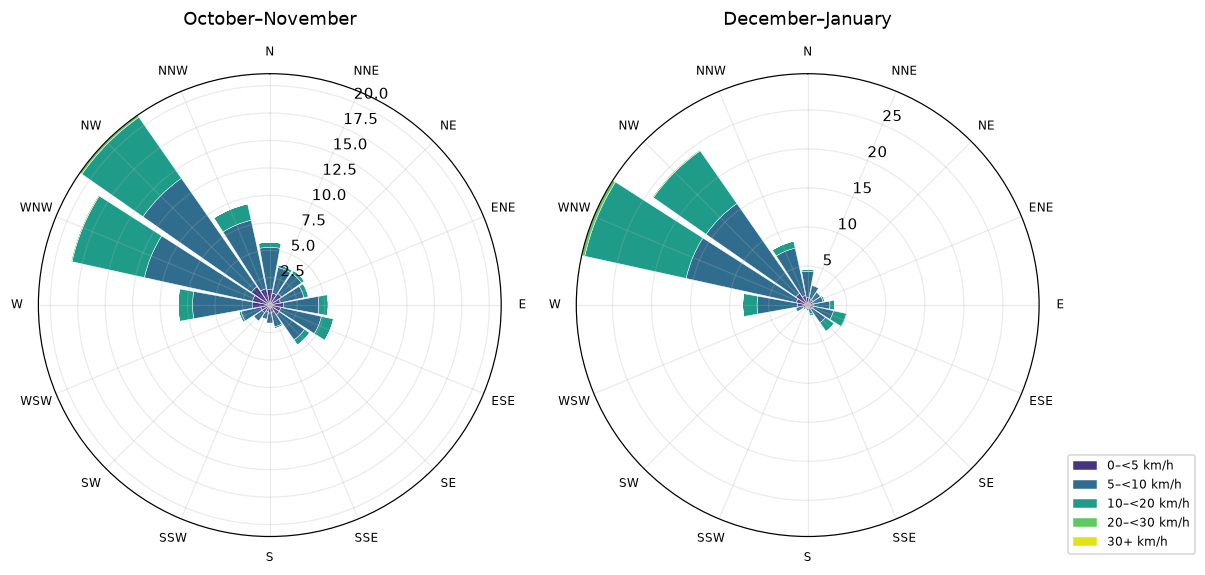

In [23]:
fig = plt.figure(figsize=(11, 5.2))
for position, (months, title) in enumerate([([10, 11], "October–November"),
                                           ([12, 1], "December–January")], start=1):
    part = clean[clean.index.month.isin(months)]
    table = audit.wind_rose_table(part["wind_speed_10m"], part["wind_direction_10m"])
    audit.plot_wind_rose(fig.add_subplot(1, 2, position, projection="polar"), table, title)
    print(f"{title}: {table.loc[['W', 'WNW', 'NW', 'NNW']].to_numpy().sum():.1f}% of non-calm hours "
          f"from W–NNW; calm hours {(part['wind_speed_10m'] == 0).mean():.2%}")
fig.axes[-1].legend(loc="lower right", bbox_to_anchor=(1.35, -0.05), fontsize=8)
plt.show()

### Observations (pre-shift period, 2003 to 31 Oct 2024)

- **Stagnation is most common early in the season:** hours with wind < 5 km/h are **19.8 % in October and 17.5 % in November**, falling to 15.3 % (Dec), 12.2 % (Jan) and 10.9 % (Feb). Mean wind rises from 7.6 to 9.7 km/h over the same months. Exactly calm hours are rare (0.03 %), so "stagnant" means *slow*, not zero.

- **Nights get colder and more humid into January:** mean 00–05 h temperature falls 21.0 → 15.9 → 10.9 → **9.2 °C (Jan)**, and night humidity rises 77.5 % → **88.4 % (Jan)**, i.e. the fog/haze regime.

- **Almost no rain to clean the air:** wet hours are 2.2 % (Oct), 1.2 % (Nov), 1.6 % (Dec), then 4.8 % (Jan) and 5.1 % (Feb).

- **Direction:** in October–November **57.4 %** of non-calm hours blow from W–NNW (the NW and WNW sectors dominate); in December–January it is **70.6 %** (WNW and NW dominate). Both are flows from the Punjab/Haryana side.

### Conclusion: hypotheses to test once PM2.5 is joined (not findings)

- **H1.** Low wind speed and cold humid nights both raise PM2.5, but they peak in *different months*: stagnation by wind speed in Oct–Nov, cold humid nights in Dec–Jan. If PM2.5 stays high in Dec–Jan, 10 m wind speed alone will not explain it, which points to a **shallow night-time mixing layer**.

- **H2.** NW-sector wind in Oct–Nov raises PM2.5 through smoke transport, which is the case for fire counts and a wind-direction interaction.

- **H3.** With so few rainy hours in Oct–Dec, *days since rain* may matter more than rain itself.

- **Open item O2:** check whether `boundary_layer_height` (and dew point) can be requested from the archive; mixing-layer depth is the variable the data above hints is missing.

---
## Step 9 · How persistent is the weather itself?

**What we are looking for.** The autocorrelation at lag *h* says how much a variable at time *t* tells you about the same variable at *t+h*.
For us, *h* = 24, 48 and 72 hours, so this sets expectations for what weather **known at issue time** can contribute to a 1-3 day forecast.

**A trap:** the raw autocorrelation is inflated by cycles. The sun guarantees that 24 h ago looks like now, even if the *weather* is unpredictable.
So we also compute it after **removing the mean month × hour cycle**, which isolates the weather-driven part.
Wind direction is analysed as *u/v* components, never as raw degrees.

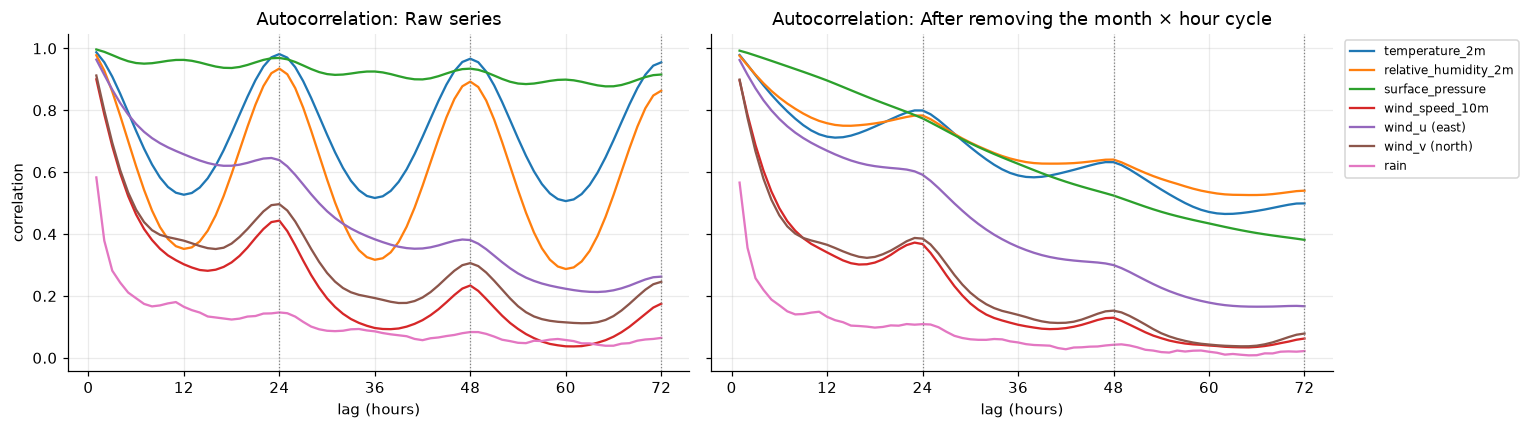

raw             deseasonalised            
                        24    48    72             24    48    72
temperature_2m        0.98  0.97  0.95           0.80  0.63  0.50
relative_humidity_2m  0.93  0.89  0.86           0.78  0.64  0.54
surface_pressure      0.97  0.93  0.92           0.77  0.52  0.38
wind_speed_10m        0.44  0.23  0.17           0.37  0.13  0.06
wind_u (east)         0.64  0.38  0.26           0.59  0.30  0.17
wind_v (north)        0.50  0.31  0.25           0.39  0.15  0.08
rain                  0.15  0.08  0.06           0.11  0.04  0.02

In [24]:
components = audit.wind_components(clean["wind_speed_10m"], clean["wind_direction_10m"])
series = {
    "temperature_2m": clean["temperature_2m"],
    "relative_humidity_2m": clean["relative_humidity_2m"],
    "surface_pressure": clean["surface_pressure"],
    "wind_speed_10m": clean["wind_speed_10m"],
    "wind_u (east)": components["u"],
    "wind_v (north)": components["v"],
    "rain": clean["rain"],
}
LAGS = range(1, 73)
raw_acf = pd.DataFrame({k: audit.autocorrelation(v, LAGS) for k, v in series.items()})
anomaly_acf = pd.DataFrame({k: audit.autocorrelation(audit.deseasonalise(v), LAGS)
                            for k, v in series.items()})

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, table, title in [(axes[0], raw_acf, "Raw series"),
                         (axes[1], anomaly_acf, "After removing the month × hour cycle")]:
    table.plot(ax=ax, legend=False)
    for lag in (24, 48, 72):
        ax.axvline(lag, color="gray", ls=":", lw=0.8)
    ax.set(title=f"Autocorrelation: {title}", xlabel="lag (hours)", xticks=range(0, 73, 12))
axes[0].set_ylabel("correlation")
axes[1].legend(*axes[0].get_legend_handles_labels(), bbox_to_anchor=(1.01, 1),
               loc="upper left", fontsize=8)
plt.show()

summary = pd.concat({"raw": raw_acf.loc[[24, 48, 72]].T,
                     "deseasonalised": anomaly_acf.loc[[24, 48, 72]].T}, axis=1)
display(summary.round(2))

### Observations (pre-shift period)
| variable | raw 24 / 48 / 72 h | after removing the month × hour cycle |
|---|---|---|
| temperature | 0.98 / 0.97 / 0.95 | 0.80 / 0.63 / 0.50 |
| humidity | 0.93 / 0.89 / 0.86 | 0.78 / 0.64 / 0.54 |
| pressure | 0.97 / 0.93 / 0.92 | 0.77 / 0.52 / 0.38 |
| wind speed | 0.44 / 0.23 / 0.17 | 0.37 / 0.13 / 0.06 |
| wind u (east) | 0.64 / 0.38 / 0.26 | 0.59 / 0.30 / 0.17 |
| wind v (north) | 0.50 / 0.31 / 0.25 | 0.39 / 0.15 / 0.08 |
| rain | 0.15 / 0.08 / 0.06 | 0.11 / 0.04 / 0.02 |

- **The raw curves for temperature, humidity and pressure look nearly perfectly persistent, but much of that is the sun and the season.** The oscillation with peaks at 24, 48 and 72 h in the left panel *is* the diurnal cycle. After removing it, temperature keeps 0.50 at 72 h and pressure only 0.38.
- **Wind speed has the shortest memory:** 0.37 at 24 h and about 0.1 by 48 h. The north–south wind component behaves the same way, and rain is essentially unpredictable from its own past beyond a few hours.

### Conclusion / decisions
- **Weather observed at issue time cannot tell us tomorrow's wind**, and wind (ventilation) is the weather variable most connected to PM2.5. For a 24–72 h forecast, this is the data-side argument for the proposal's "setting (b)": weather *forecasts* issued at or before time *t*.
- **Open item O3 (time-sensitive):** archived weather forecasts cannot be recovered later. Start **logging forecast snapshots now** (a small scheduled fetch), so that the operational setting can be tested honestly by January.
- **Feature design:** long lags of wind add almost nothing; keep wind features short (current value, 6–24 h mean) and let pressure and temperature supply longer context.

---
## Step 10 · Cross-variable sanity

**What we are looking for.** Real weather variables are physically coupled. If the expected relationships are absent, suspect shifted columns or unit mix-ups.
Warm air at constant moisture is drier, so temperature and humidity should be **negatively** correlated.
Afternoon heating mixes faster upper-air momentum down to the surface, so wind should be **stronger in the afternoon** than at night.
Strongly correlated inputs are also worth knowing about, because they matter for the linear (ridge) model.

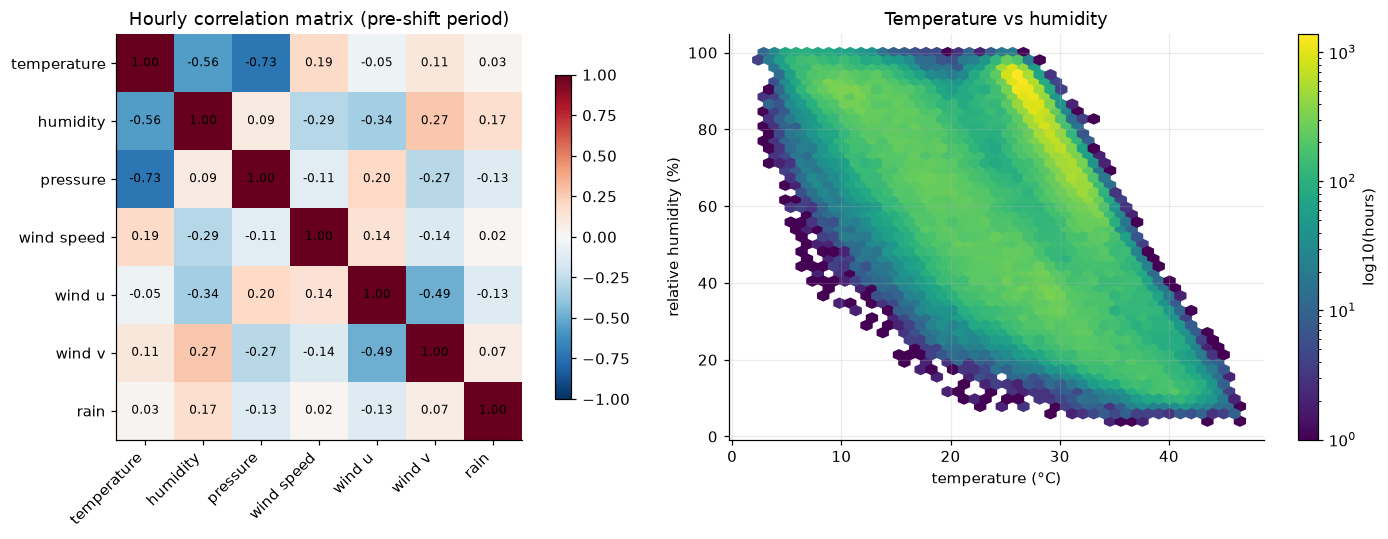

Temperature–humidity correlation, raw:                   -0.56
  after removing each month's mean:                      -0.81
  after removing the month × hour cycle (weather only):  -0.56


In [25]:
hourly = pd.DataFrame({
    "temperature": clean["temperature_2m"],
    "humidity": clean["relative_humidity_2m"],
    "pressure": clean["surface_pressure"],
    "wind speed": clean["wind_speed_10m"],
    "wind u": components["u"],
    "wind v": components["v"],
    "rain": clean["rain"],
})
corr = hourly.corr()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
image = axes[0].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
axes[0].set_yticks(range(len(corr)), corr.columns)
axes[0].grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        axes[0].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=axes[0], shrink=0.8)
axes[0].set_title("Hourly correlation matrix (pre-shift period)")

hexbin = axes[1].hexbin(hourly["temperature"], hourly["humidity"], gridsize=45, bins="log", cmap="viridis")
axes[1].set(xlabel="temperature (°C)", ylabel="relative humidity (%)", title="Temperature vs humidity")
fig.colorbar(hexbin, ax=axes[1], label="log10(hours)")
plt.show()

month_key = hourly.index.to_period("M")
within_month = hourly[["temperature", "humidity"]] - hourly[["temperature", "humidity"]].groupby(month_key).transform("mean")
anomalies = pd.DataFrame({"t": audit.deseasonalise(hourly["temperature"]),
                          "h": audit.deseasonalise(hourly["humidity"])})
print(f"Temperature–humidity correlation, raw:                   {corr.loc['temperature', 'humidity']:+.2f}")
print(f"  after removing each month's mean:                      {within_month['temperature'].corr(within_month['humidity']):+.2f}")
print(f"  after removing the month × hour cycle (weather only):  {anomalies['t'].corr(anomalies['h']):+.2f}")

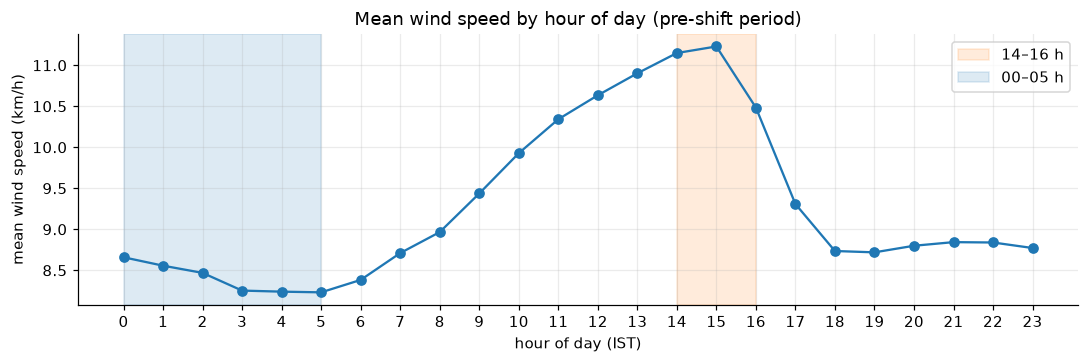

Mean wind 14–16 h: 10.95 km/h | 00–05 h: 8.40 km/h | difference +2.55 km/h


In [26]:
by_hour = clean["wind_speed_10m"].groupby(clean.index.hour).mean()
afternoon, night_mean = by_hour.loc[14:16].mean(), by_hour.loc[0:5].mean()

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(by_hour.index, by_hour.values, marker="o")
ax.axvspan(14, 16, alpha=0.15, color="tab:orange", label="14–16 h")
ax.axvspan(0, 5, alpha=0.15, color="tab:blue", label="00–05 h")
ax.set(xticks=range(24), xlabel="hour of day (IST)", ylabel="mean wind speed (km/h)",
       title="Mean wind speed by hour of day (pre-shift period)")
ax.legend()
plt.show()
print(f"Mean wind 14–16 h: {afternoon:.2f} km/h | 00–05 h: {night_mean:.2f} km/h | "
      f"difference {afternoon - night_mean:+.2f} km/h")

### Observations (pre-shift period)
- **Temperature and humidity are negatively correlated, as physics requires:** −0.56 on the raw hourly data. Removing each month's mean makes it **−0.81**, because the diurnal cycle (warm afternoon = dry air) is then the dominant signal. Removing the whole month × hour cycle leaves the *weather-driven* part: **−0.56**.
- **Temperature and pressure are strongly anti-correlated (−0.73)**, which is the seasonal heat low seen in step 2.
- **Wind speed is higher in the afternoon:** 10.95 km/h at 14–16 h against 8.40 km/h at 00–05 h (**+2.55 km/h**), the usual signature of daytime mixing, and the reason nights are the stagnant hours.
- Wind components relate to humidity in a sensible way (u: −0.34, v: +0.27, i.e. dry air comes with westerlies, humid air with southerly flow). Rain is weakly related to everything (|r| ≤ 0.17).
- No pair of variables is close to ±1 (the strongest is temperature–pressure at −0.73), so there are no duplicated or shifted columns.

### Conclusion
- ✅ The variables are physically coherent: no sign of mislabelled columns, unit mix-ups or time-shifted fields.
- Temperature, pressure and humidity carry overlapping information (|r| up to 0.73). That does not matter for tree models but **can destabilise the ridge baseline**, so the ridge uses regularisation (as already planned) and its coefficients are not interpreted individually.

---
## Step 11 · Documentation and decisions

**What we are looking for.** An audit is only useful if its conclusions are written down where the next step will read them.
The decisions below are carried into `data/README.md` (the data dictionary) and become requirements for the cleaning step and for the leakage tests.

### Decisions taken in this audit

| ID | Decision | Where it takes effect |
|---|---|---|
| D1 | Keep the full 2003-01-01 → 2026-10-11 file as the raw archive; trim to the PM2.5 station overlap at join time. | join step |
| D2 | Timestamps are IST; no shift. Make the zone explicit with `tz_localize("Asia/Kolkata")`; convert FIRMS (UTC) at its join. | cleaning |
| D3 | No clipping or deletion: every flagged value was physical. Pressure review range is 960–1010 hPa. | cleaning, tests |
| D4 | Wind direction is never used in degrees: use u/v; use `direction % 360`; calm hours get u = v = 0. | features |
| D5 | Rain = wet flag + amount + rolling totals + hours since last rain; excluded from flat-line checks. | features |
| D6 | Wind speed has a level shift at ~2024-11-06; pre-shift period (to 2024-10-31) used for descriptive wind statistics until O1 is resolved. | everything that uses wind |
| D7 | Four local seasons (Dec–Feb, Mar–Jun, Jul–Sep, Oct–Nov), reused for PM2.5. | evaluation by regime |
| D8 | Compare seasons like for like (December → following season-year, drop incomplete seasons). | all season comparisons |

### Open items

| ID | Item | Why it matters |
|---|---|---|
| O1 | Re-fetch with a pinned reanalysis model and check whether the Nov-2024 wind shift disappears. | the final test season is after the break |
| O2 | Check if `boundary_layer_height` (and dew point) can be fetched from the archive. | mixing depth is the missing physical driver (H1) |
| O3 | Start logging weather-forecast snapshots now. | archived forecasts cannot be recovered later |
| O4 | Re-run this notebook after O1; update decisions D6 and the README. | keeps the audit honest |

